In [1]:
# Cell 1 — imports + paths
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "data"  # change if needed

P_SOM_PKL = os.path.join(DATA_DIR, "som_200_5colours_rand.pkl")
P_WCLUST  = os.path.join(DATA_DIR, "weighted_clusters_5c_1t200.npy")

print("SOM PKL:", P_SOM_PKL, "| exists:", os.path.exists(P_SOM_PKL))
print("Weighted clusters:", P_WCLUST, "| exists:", os.path.exists(P_WCLUST))


SOM PKL: data/som_200_5colours_rand.pkl | exists: True
Weighted clusters: data/weighted_clusters_5c_1t200.npy | exists: True


In [22]:
# Cell 2 — load weighted_clusters + basic inspection
weighted_clusters = np.load(P_WCLUST, allow_pickle=False)

print("weighted_clusters:")
print("  shape:", weighted_clusters.shape)
print("  dtype:", weighted_clusters.dtype)
print("  min/max:", np.nanmin(weighted_clusters), np.nanmax(weighted_clusters))
print("  unique (first 20):", np.unique(weighted_clusters)[:20])


weighted_clusters:
  shape: (201, 40000)
  dtype: int64
  min/max: 0 39997
  unique (first 20): [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]


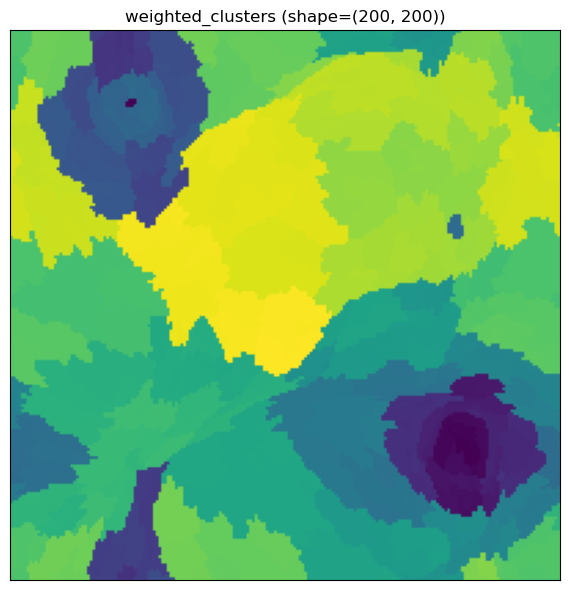

In [20]:
# Cell 3 — visualize weighted_clusters (try reshape to 200x200 if it's 1D)
H, W = 200, 200

def as_grid(a, i,H=200, W=200):
    a = np.asarray(a[i])
    if a.shape == (H, W):
        return a
    if a.ndim == 1 and a.size == H * W:
        return a.reshape(H, W)
    return a  # fallback

wc_grid = as_grid(weighted_clusters,100 ,H, W)

plt.figure(figsize=(6, 6))
plt.imshow(wc_grid)
plt.title(f"weighted_clusters (shape={wc_grid.shape})")
plt.xticks([]); plt.yticks([])
plt.tight_layout()
plt.show()


In [23]:
import pandas as pd
import numpy as np

cluster_counts = [
    len(np.unique(weighted_clusters[i]))
    for i in range(weighted_clusters.shape[0])
]

df_clusters = pd.DataFrame({
    "level": np.arange(len(cluster_counts)),
    "num_clusters": cluster_counts
})

df_clusters.head(), df_clusters.tail()


(   level  num_clusters
 0      0             1
 1      1             1
 2      2             4
 3      3             9
 4      4            16,
      level  num_clusters
 196    196         38416
 197    197         38809
 198    198         39204
 199    199         39601
 200    200         39998)

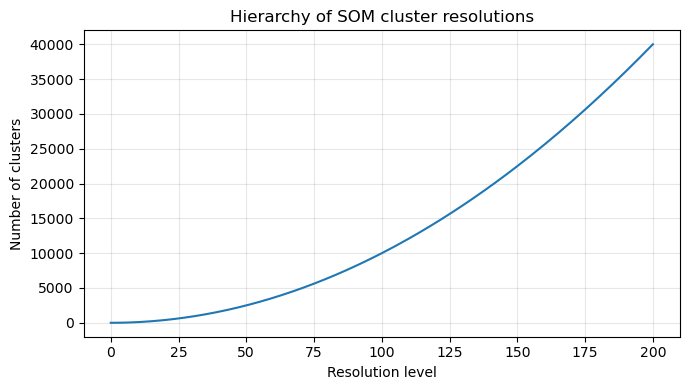

In [24]:
plt.figure(figsize=(7,4))
plt.plot(df_clusters["level"], df_clusters["num_clusters"])
plt.xlabel("Resolution level")
plt.ylabel("Number of clusters")
plt.title("Hierarchy of SOM cluster resolutions")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


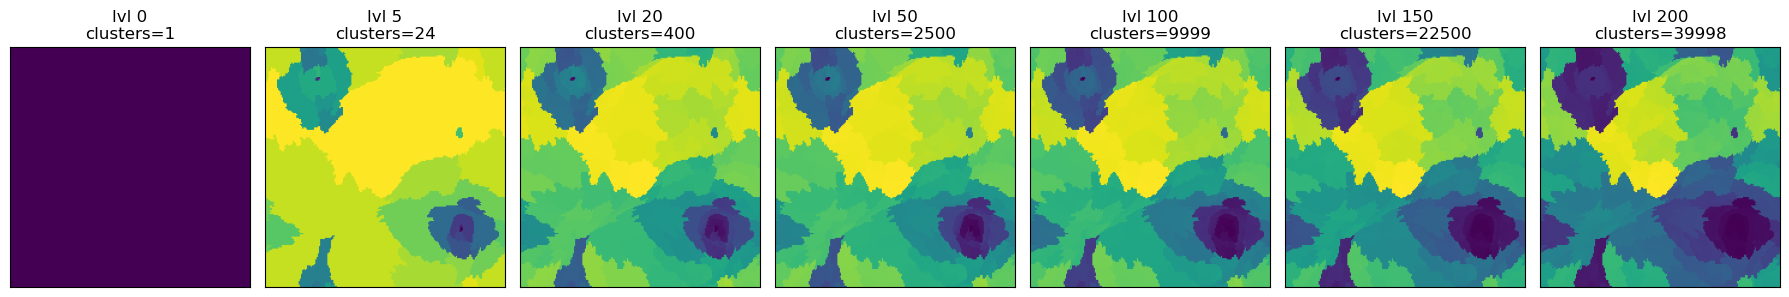

In [25]:
levels = [0, 5, 20, 50, 100, 150, 200]

fig, axs = plt.subplots(1, len(levels), figsize=(18, 3))

for ax, lvl in zip(axs, levels):
    grid = weighted_clusters[lvl].reshape(H, W)
    ax.imshow(grid)
    ax.set_title(f"lvl {lvl}\nclusters={len(np.unique(grid))}")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()


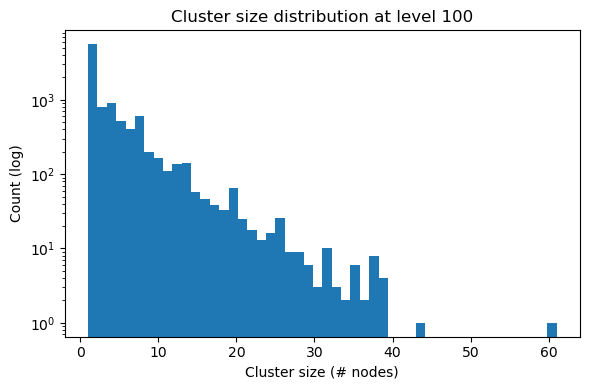

In [26]:
level = 100  # try a few values
labels = weighted_clusters[level]

cluster_sizes = np.bincount(labels)
cluster_sizes = cluster_sizes[cluster_sizes > 0]

plt.figure(figsize=(6,4))
plt.hist(cluster_sizes, bins=50, log=True)
plt.xlabel("Cluster size (# nodes)")
plt.ylabel("Count (log)")
plt.title(f"Cluster size distribution at level {level}")
plt.tight_layout()
plt.show()


In [4]:
# Cell 4 — load the SOM pickle + quick introspection
with open(P_SOM_PKL, "rb") as f:
    som_obj = pickle.load(f)

print("Loaded SOM object type:", type(som_obj))

# If it's a dict-like container, list keys
if isinstance(som_obj, dict):
    print("Dict keys:", sorted(list(som_obj.keys()))[:50], "... (truncated)" if len(som_obj) > 50 else "")
else:
    # show useful attributes
    attrs = [a for a in dir(som_obj) if not a.startswith("_")]
    print("Num public attrs:", len(attrs))
    print("Sample attrs:", attrs[:60])


Loaded SOM object type: <class 'somoclu.train.Somoclu'>
Num public attrs: 19
Sample attrs: ['activation_map', 'bmus', 'cluster', 'clusters', 'codebook', 'get_bmus', 'get_surface_state', 'load_bmus', 'load_codebook', 'load_umatrix', 'n_dim', 'n_vectors', 'train', 'umatrix', 'update_data', 'view_activation_map', 'view_component_planes', 'view_similarity_matrix', 'view_umatrix']


In [5]:
# Cell 5 — helper to *find* a plausible U-matrix / distance map inside the object
def find_umatrix_candidate(obj, H=200, W=200):
    """
    Tries common SOM libraries/fields:
      - MiniSom: distance_map()
      - somoclu: umatrix, get_umatrix()
      - generic: attributes containing 'u', 'umatrix', 'distance', 'dist', 'umat'
    Returns (name, array) or (None, None).
    """
    # common methods
    for meth in ["distance_map", "umatrix", "get_umatrix", "getUmatrix", "get_u_matrix"]:
        if hasattr(obj, meth) and callable(getattr(obj, meth)):
            try:
                out = getattr(obj, meth)()
                arr = np.asarray(out)
                if arr.size == H * W or arr.shape == (H, W):
                    return f"method:{meth}", arr.reshape(H, W) if arr.size == H * W else arr
            except Exception:
                pass

    # common attributes
    candidates = []
    for name in dir(obj):
        if name.startswith("_"):
            continue
        lname = name.lower()
        if any(k in lname for k in ["umatrix", "u_matrix", "distance", "distmap", "dist_map", "umat"]):
            try:
                val = getattr(obj, name)
                if callable(val):
                    continue
                arr = np.asarray(val)
                if arr.size == H * W or arr.shape == (H, W):
                    candidates.append((name, arr.reshape(H, W) if arr.size == H * W else arr))
            except Exception:
                pass

    if candidates:
        # pick the first; you can inspect others if needed
        return f"attr:{candidates[0][0]}", candidates[0][1]

    # dict case
    if isinstance(obj, dict):
        for k, v in obj.items():
            lk = str(k).lower()
            if any(s in lk for s in ["umatrix", "u_matrix", "distance", "dist", "umat"]):
                try:
                    arr = np.asarray(v)
                    if arr.size == H * W or arr.shape == (H, W):
                        return f"dict:{k}", arr.reshape(H, W) if arr.size == H * W else arr
                except Exception:
                    pass

    return None, None

name, umat = find_umatrix_candidate(som_obj, H=200, W=200)
print("U-matrix candidate:", name)
print("U-matrix found:", umat is not None)
if umat is not None:
    print("  shape:", umat.shape, "dtype:", umat.dtype, "min/max:", float(np.nanmin(umat)), float(np.nanmax(umat)))


U-matrix candidate: attr:umatrix
U-matrix found: True
  shape: (200, 200) dtype: float32 min/max: 0.013760206289589405 0.8203610181808472


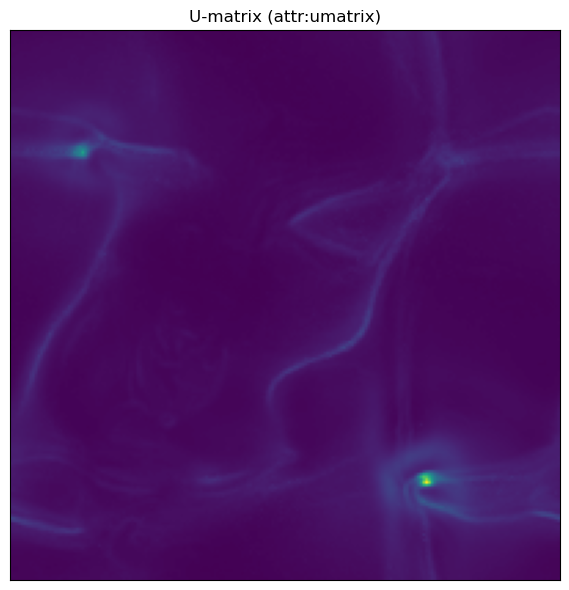

In [6]:
# Cell 6 — plot U-matrix (if found)
if umat is None:
    print("No U-matrix-like array found in the pickle with the current heuristics.")
else:
    plt.figure(figsize=(6, 6))
    plt.imshow(umat)
    plt.title(f"U-matrix ({name})")
    plt.xticks([]); plt.yticks([])
    plt.tight_layout()
    plt.show()


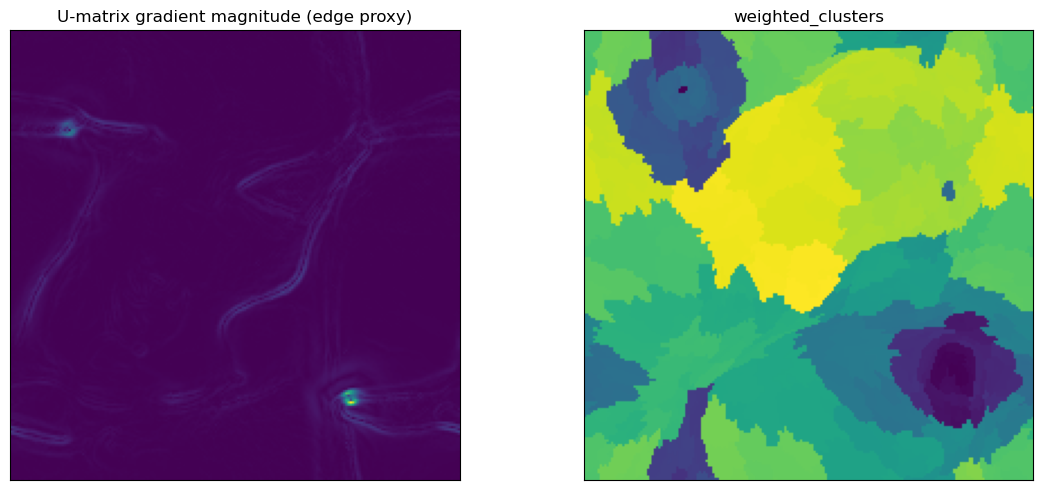

In [28]:
# Cell 7 — optional: overlay U-matrix edges vs clusters (quick sanity visual)
# (This is not “scientific”; it's just to see if cluster boundaries align with high U-matrix.)
if umat is not None:
    # cheap edge proxy: local gradient magnitude
    gy, gx = np.gradient(umat.astype(np.float64))
    edge = np.sqrt(gx*gx + gy*gy)

    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    axs[0].imshow(edge)
    axs[0].set_title("U-matrix gradient magnitude (edge proxy)")
    axs[0].set_xticks([]); axs[0].set_yticks([])

    axs[1].imshow(wc_grid)
    axs[1].set_title("weighted_clusters")
    axs[1].set_xticks([]); axs[1].set_yticks([])

    plt.tight_layout()
    plt.show()
else:
    print("Skipping overlay: umat not available.")


In [8]:
# Cell 8 — if umat not found: deeper dump of dict keys / array-like fields
def summarize_arrays_in(obj, max_items=60):
    found = []
    if isinstance(obj, dict):
        items = obj.items()
    else:
        items = [(a, getattr(obj, a)) for a in dir(obj) if not a.startswith("_")]

    for k, v in items:
        try:
            if callable(v):
                continue
            arr = np.asarray(v)
            if arr.ndim >= 1 and arr.size > 0 and np.issubdtype(arr.dtype, np.number):
                found.append((str(k), arr.shape, str(arr.dtype)))
        except Exception:
            pass

    found = sorted(found, key=lambda x: np.prod(x[1]) if len(x[1]) else 0, reverse=True)
    print(f"Found {len(found)} numeric array-like fields.")
    for row in found[:max_items]:
        print(" ", row)

summarize_arrays_in(som_obj, max_items=80)


Found 3 numeric array-like fields.
  ('bmus', (10395422, 2), 'int32')
  ('codebook', (200, 200, 5), 'float32')
  ('umatrix', (200, 200), 'float32')
